<a href="https://colab.research.google.com/github/Thathsara-Devindi/ANN-Dry-Bean-Classification/blob/main/ANN_cw1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#T1 - Problem Definition and Data Preparation

Project title: Comparative Evaluation of MLP and RBF Neural Networks for Dry Bean Classification

Problem: Predict the variety of a dry bean from 16 numerical morphological measurements

Intended user: Agricultural researchers or quality-control personnel who need to identify bean varieties from measured shape characteristics

Prediction target: One of seven bean varieties (BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA)

Unit of observation: One bean sample represented by 16 extracted morphological features.

Practical value: Investigate whether automated prediction from measured features can assist bean-variety identification. A possible decision-support application is sorting or quality inspection, but deployment performance has not been established.

Data source and provenance: UCI Machine Learning Repository, Dry Bean Dataset (ID 602), 13,611 original observations, 16 numeric features and 7 classes.

Dataset access and licence: CC BY 4.0. UCI dataset page.

Original dataset authors: Koklu and Ozkan (2020). UCI DOI: 10.24432/C50S4B.




Ethical and practical considerations:
Errors in prediction can lead to misidentification of varieties. The results of the published data set are not necessarily indicative of the reliability of the data when collected under new conditions. The system should not be considered as validated for use in the real world.



Dataset: UCI Dry Bean (ID 602), https://archive.ics.uci.edu/dataset/602/dry+bean. Koklu & Ozkan (2020), DOI 10.24432/C50S4B, CC BY 4.0. 13,611 observations, 16 numeric features, seven target classes (verify actual loaded counts in the output)

#1. Environment Setup

In [ ]:
%pip -q install ucimlrepo==0.0.7

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
BASE = Path('/content/drive/MyDrive/ANN_DryBean_CW1')
DATA_DIR = BASE / 'data'
FIG_DIR = BASE / 'figures'
ARTIFACT_DIR = BASE / 'artifacts'
for folder in (BASE, DATA_DIR, FIG_DIR, ARTIFACT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Project files saved to:', BASE)

Mounted at /content/drive
Project files saved to: /content/drive/MyDrive/ANN_DryBean_CW1


#2. Download the original data from UCI

Feature - measurement for model

Target - The answer the model needs to predict

Row/observation - bean sample

In [ ]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

bean_data = fetch_ucirepo(id=602)
X_raw = bean_data.data.features.copy()
y_raw = bean_data.data.targets.iloc[:, 0].copy()

raw_df = X_raw.copy()
raw_df['Class'] = y_raw.astype('string').str.strip()
feature_cols = list(X_raw.columns)

print('Original dataset shape (rows, columns):', raw_df.shape)
print('Number of features:', len(feature_cols))
print('Target classes:', sorted(raw_df['Class'].dropna().unique().tolist()))
print('First five observations:')
display(raw_df.head())
raw_df.to_csv(DATA_DIR / 'dry_bean_original.csv', index=True, index_label='original_row_id')
print('Saved original data to:', DATA_DIR / 'dry_bean_original.csv')

Original dataset shape (rows, columns): (13611, 17)
Number of features: 16
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
First five observations:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Saved original data to: /content/drive/MyDrive/ANN_DryBean_CW1/data/dry_bean_original.csv


#3. Basic data audit: missing, duplicates, classes, feature statistics


In [ ]:
print('Total rows:', len(raw_df))
print('Number of input features:', len(feature_cols))
print('Missing values in whole dataset:', int(raw_df.isna().sum().sum()))
print('Exact duplicate rows:', int(raw_df.duplicated().sum()))
print('\nMissing values by column:')
display(raw_df.isna().sum().to_frame('missing_count'))
print('\nBean class counts:')
display(raw_df['Class'].value_counts().rename_axis('Class').to_frame('count'))
print('\nNumerical feature statistics:')
display(raw_df[feature_cols].describe().T)
print('\nNon-positive values in Area / Perimeter (if present):')
for name in ('Area', 'Perimeter'):
    if name in raw_df.columns:
        print(name, int((raw_df[name] <= 0).sum()))

Total rows: 13611
Number of input features: 16
Missing values in whole dataset: 0
Exact duplicate rows: 68

Missing values by column:


,missing_count
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0



Bean class counts:


,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677



Non-positive values in Area / Perimeter (if present):
Area 0
Perimeter 0


##T1b - Data audit: observations and decisions

The original data set has 13611 observations and 16 numeric variables. The audit found 0 missing cells and 68 exact duplicate rows. There are no non-positive numbers in the Area and Perimeter columns. Another check later on also revealed 0 cases with the same features but different class labels, for which the exact duplicates were excluded prior to splitting, resulting in 13543 observations. This decreases the chances of having the same example in the training data and the test data.

The frequencies of the seven classes are not equal (3546 for DERMASON and 522 for BOMBAY in the original data). So, stratified partitioning is applied and macro-F1 is considered as an important primary metric in addition to accuracy and per-class recall. There are also different numerical ranges of the features which encourages training only standardization. Values that could be extreme will be checked, but not removed

#4. check contradictory examples and clean duplicate observations

In [ ]:
# Same feature vector but contradictory bean labels?
conflicting_vectors = raw_df.groupby(feature_cols, dropna=False)['Class'].nunique(dropna=False)
num_conflicting_vectors = int((conflicting_vectors > 1).sum())
print('Feature vectors with conflicting target labels:', num_conflicting_vectors)
if num_conflicting_vectors > 0:
    raise ValueError('Conflicting feature labels found: inspect these before removing duplicates or splitting.')

clean_df = raw_df.drop_duplicates().copy()  # preserve original row index
removed_duplicates = len(raw_df) - len(clean_df)
print('Exact duplicate observations removed:', removed_duplicates)
print('Cleaned dataset size:', clean_df.shape)
assert clean_df[feature_cols].notna().all().all(), 'Missing features need explicit treatment.'
assert clean_df['Class'].notna().all(), 'Missing class labels need explicit treatment.'
clean_df.to_csv(DATA_DIR / 'dry_bean_clean.csv', index=True, index_label='original_row_id')

Feature vectors with conflicting target labels: 0
Exact duplicate observations removed: 68
Cleaned dataset size: (13543, 17)


#5. Freeze train/validation/test splits

A stratified split of 70/15/15 was chosen to ensure sufficient observations for training the neural networks and leave out some observations for model selection and final testing. Previously, exact duplicates were removed prior to splitting. The same saved partitions will be reused by every model. No identifiers were included for the specimens or groups and any dependencies between observations collected cannot be independently verified

In [ ]:
from sklearn.model_selection import train_test_split

SPLIT_SEED = 42
train_ids, remaining_ids = train_test_split(
    clean_df.index.to_numpy(), test_size=0.30,
    random_state=SPLIT_SEED, stratify=clean_df['Class']
)
val_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.50,
    random_state=SPLIT_SEED,
    stratify=clean_df.loc[remaining_ids, 'Class']
)

train_df = clean_df.loc[train_ids].copy()
val_df = clean_df.loc[val_ids].copy()
test_df = clean_df.loc[test_ids].copy()

assert len(set(train_ids) & set(val_ids)) == 0
assert len(set(train_ids) & set(test_ids)) == 0
assert len(set(val_ids) & set(test_ids)) == 0
assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)

for name, frame in [('Train',train_df),('Validation',val_df),('Test',test_df)]:
    print(f'{name}: {len(frame)} samples ({100*len(frame)/len(clean_df):.2f}%)')
    print(frame['Class'].value_counts(normalize=True).round(3).to_dict())

Train: 9480 samples (70.00%)
{'DERMASON': 0.262, 'SIRA': 0.195, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.12, 'BARBUNYA': 0.098, 'BOMBAY': 0.039}
Validation: 2031 samples (15.00%)
{'DERMASON': 0.262, 'SIRA': 0.194, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.12, 'BARBUNYA': 0.098, 'BOMBAY': 0.038}
Test: 2032 samples (15.00%)
{'DERMASON': 0.262, 'SIRA': 0.195, 'SEKER': 0.15, 'HOROZ': 0.137, 'CALI': 0.121, 'BARBUNYA': 0.097, 'BOMBAY': 0.038}


#6. EDA plot - class distribution (Train only)

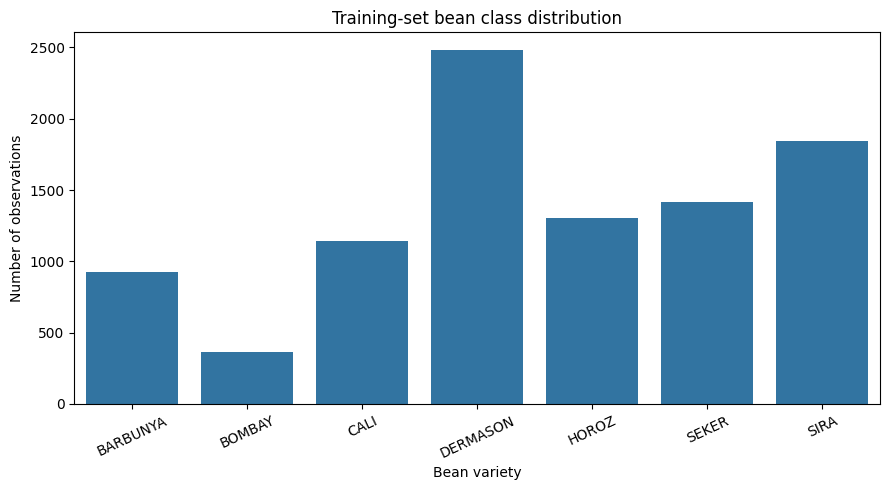

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.countplot(data=train_df, x='Class', order=sorted(train_df['Class'].unique()))
plt.title('Training-set bean class distribution')
plt.xlabel('Bean variety')
plt.ylabel('Number of observations')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure1_training_class_distribution.png', dpi=180)
plt.show()

Figure 1 - The training set class distribution is imbalanced: DERMASON is the most frequent variety and BOMBAY the least frequent. The overall accuracy could mask poor performance for smaller classes. So plan to report macro-F1, accuracy, a confusion matrix and class-level precision/recall/F1 in T4.Class proportions are fairly similar between train, validation and test partitions.

## Bean ares by class (Train only)

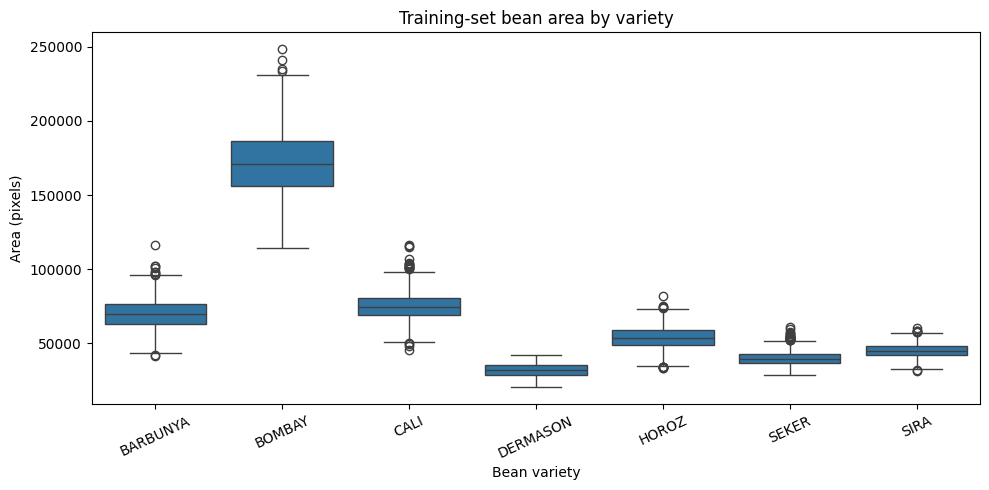

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df, x='Class', y='Area', order=sorted(train_df['Class'].unique()))
plt.title('Training-set bean area by variety')
plt.xlabel('Bean variety')
plt.ylabel('Area (pixels)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure2_area_by_class.png', dpi=180)
plt.show()

Figure 2 - The Area measurement varies considerably among bean varieties: BOMBAY shows significantly higher measurement than most of the other varieties. There are points outside the boxplot whiskers in a few classes. These are potential outlier data points but not necessarily incorrect records. They are retained unless a defensible reason for removal in terms of data quality is identified. Area may be used for classification but it is not likely to be sufficient for distinguishing all the classes


## Feature correlation (Train only)

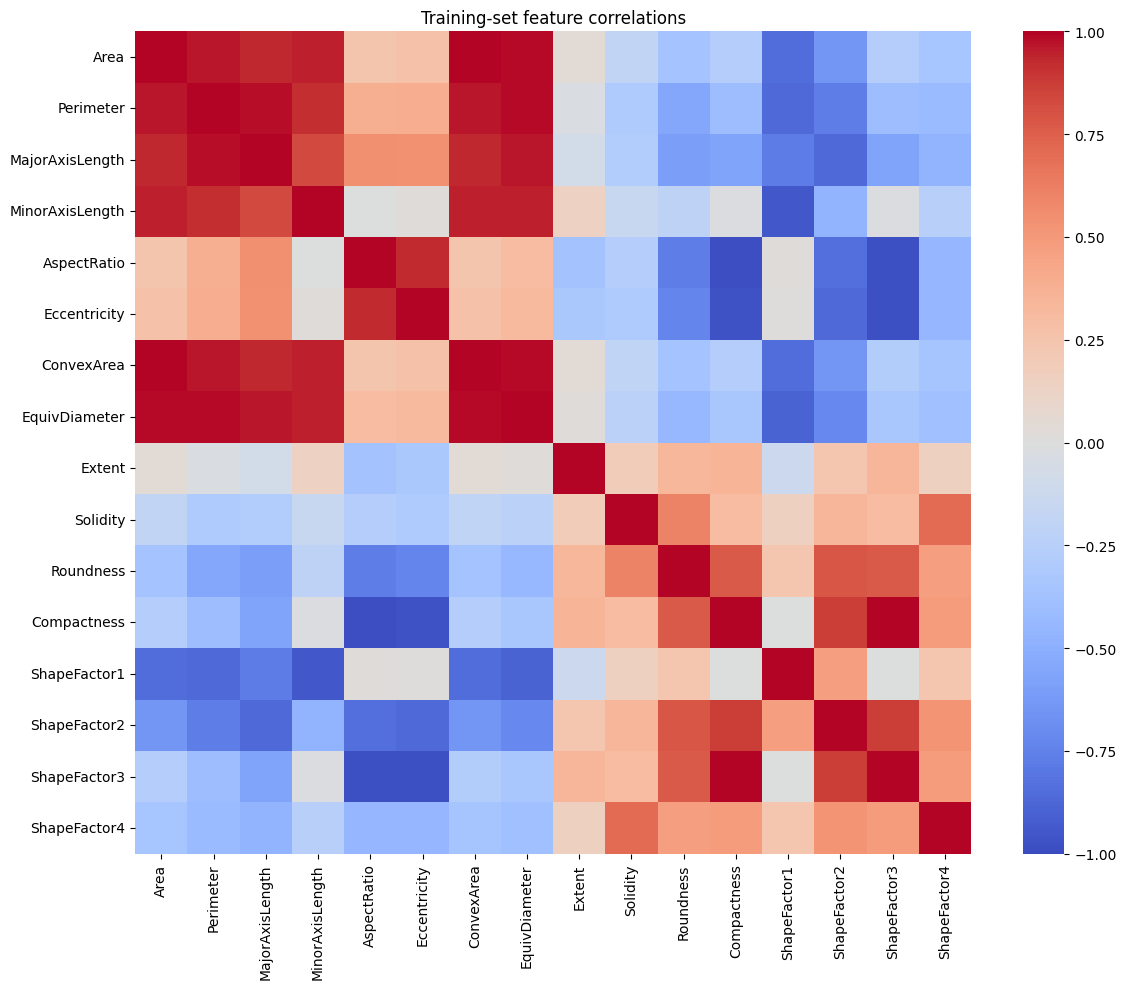

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(train_df[feature_cols].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Training-set feature correlations')
plt.tight_layout()
plt.savefig(FIG_DIR / 'T1_Figure3_training_feature_correlations.png', dpi=180)
plt.show()

Figure 3 - The heatmap shows strong positive correlations among size related features such as Area, ConvexArea and EquivDiameter.It also provides highly related shape descriptors such as Compactness and ShapeFactor3. These relationships show potential for redundant information but correlation alone does not provide information about which inputs should be eliminated. All 16 inputs are retained for the initial fair comparison and may be justified and evaluated as optional feature reduction experiments later

#7. Fit preprocessing on training data only

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
label_encoder = LabelEncoder()

X_train = preprocessor.fit_transform(train_df[feature_cols]).astype(np.float32)
X_val = preprocessor.transform(val_df[feature_cols]).astype(np.float32)
X_test = preprocessor.transform(test_df[feature_cols]).astype(np.float32)
y_train = label_encoder.fit_transform(train_df['Class'])
y_val = label_encoder.transform(val_df['Class'])
y_test = label_encoder.transform(test_df['Class'])

print('X_train / y_train:', X_train.shape, y_train.shape)
print('X_val / y_val:', X_val.shape, y_val.shape)
print('X_test / y_test:', X_test.shape, y_test.shape)
print('Class mapping:', dict(enumerate(label_encoder.classes_.tolist())))
print('Training-set mean after scaling (first 3 features):', np.round(X_train.mean(axis=0)[:3], 3))

X_train / y_train: (9480, 16) (9480,)
X_val / y_val: (2031, 16) (2031,)
X_test / y_test: (2032, 16) (2032,)
Class mapping: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Training-set mean after scaling (first 3 features): [ 0.  0. -0.]


##Why the preprocessing is leakage safe

After removing exact duplicates, the stratified 70/15/15 partition is fixed with seed 42 and its original row indices are saved. This ratio ensures that most observations are used for training and also creates a separate validation set and final test set. These same splits will be used for all models. Model features do not include the target (Class) or saved row identifiers. The median imputer and standard scaler are only trained on the training data and then transformed on the validation and test data with the parameters learned in the training phase. The target encoder is also trained on the training labels. No augmentation is used. The test set is not used for tuning, selection, or debugging of model performance. Independence between the different observed beans is limited as specimen/group identifiers are not available

In [ ]:
# Additional T1 verification checks

assert 'Class' not in feature_cols
assert 'original_row_id' not in feature_cols

# Each partition must contain every target class.
expected_classes = set(range(7))

for name, X, y in [
    ('Train', X_train, y_train),
    ('Validation', X_val, y_val),
    ('Test', X_test, y_test)
]:
    assert X.shape[1] == 16
    assert np.isfinite(X).all()
    assert set(np.unique(y)) == expected_classes
    print(f'{name}: shape, finite values and classes OK')

# No repeated feature vector remains after cleaning.
assert not clean_df.duplicated(subset=feature_cols).any()

print('Additional T1 verification checks passed.')

Train: shape, finite values and classes OK
Validation: shape, finite values and classes OK
Test: shape, finite values and classes OK
Additional T1 verification checks passed.


#8. save exact split IDs, settings, processed data and evidence

In [ ]:
import json, sys, platform
import joblib
import sklearn
import ucimlrepo

np.savez_compressed(
    DATA_DIR / 'split_original_row_ids.npz',
    train_ids=train_ids.astype(np.int64),
    val_ids=val_ids.astype(np.int64),
    test_ids=test_ids.astype(np.int64)
)
np.savez_compressed(
    DATA_DIR / 't1_processed_splits.npz',
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test
)
joblib.dump(preprocessor, ARTIFACT_DIR / 't1_train_fitted_preprocessor.joblib')
joblib.dump(label_encoder, ARTIFACT_DIR / 't1_label_encoder.joblib')

summary = {
    'dataset_name': 'UCI Dry Bean',
    'dataset_uci_id': 602,
    'dataset_url': 'https://archive.ics.uci.edu/dataset/602/dry+bean',
    'dataset_licence': 'CC BY 4.0',
    'raw_rows': int(len(raw_df)),
    'features': feature_cols,
    'total_missing_cells': int(raw_df.isna().sum().sum()),
    'exact_duplicate_rows_removed': int(removed_duplicates),
    'conflicting_feature_vectors': int(num_conflicting_vectors),
    'clean_rows': int(len(clean_df)),
    'class_counts_original': {str(k):int(v) for k,v in raw_df['Class'].value_counts().items()},
    'split_seed': SPLIT_SEED,
    'split_counts': {'train':len(train_df),'validation':len(val_df),'test':len(test_df)},
    'split_strategy': 'stratified random 70/15/15 after exact duplicate removal',
    'preprocessing': 'training-fitted median imputer and standard scaler',
    'target_encoding': {str(name):int(i) for i,name in enumerate(label_encoder.classes_)},
    'versions': {
        'python':sys.version.split()[0],
        'pandas':pd.__version__,
        'numpy':np.__version__,
        'scikit_learn':sklearn.__version__,
        'ucimlrepo': '0.0.7',
        'platform':platform.platform()
    }
}
with open(ARTIFACT_DIR / 't1_run_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('Saved T1 artifacts to Drive:', BASE)
print('T1 output files:')
for item in sorted(BASE.rglob('*')):
    if item.is_file():
        print('-', item.relative_to(BASE))

Saved T1 artifacts to Drive: /content/drive/MyDrive/ANN_DryBean_CW1
T1 output files:
- artifacts/t1_label_encoder.joblib
- artifacts/t1_run_summary.json
- artifacts/t1_train_fitted_preprocessor.joblib
- data/dry_bean_clean.csv
- data/dry_bean_original.csv
- data/split_original_row_ids.npz
- data/t1_processed_splits.npz
- figures/T1_Figure1_training_class_distribution.png
- figures/T1_Figure2_area_by_class.png
- figures/T1_Figure3_training_feature_correlations.png


# T2 – Implement and Verify Learning from First Principles

T1 fitted preprocessing and target encoding are reused unchanged. So there is no new fitting on validation or test data. Both original split indices and T2 subset positions are saved for reproducibility

In [1]:
#Load T1 training/validation artifacts (not test performance)
from pathlib import Path
import numpy as np
import pandas as pd
import json
import platform
import sys

t2_base = Path('/content/drive/MyDrive/ANN_DryBean_CW1')
t2_path = t2_base / 'data' / 't1_processed_splits.npz'
if not t2_path.exists():
    from google.colab import drive
    drive.mount('/content/drive')
if not t2_path.exists():
    raise FileNotFoundError(f'Missing {t2_path}. Run T1 through its save-artifacts cell first.')

t2_artifacts = t2_base / 'artifacts'
t2_figures = t2_base / 'figures'
t2_artifacts.mkdir(parents=True, exist_ok=True)
t2_figures.mkdir(parents=True, exist_ok=True)
with np.load(t2_path) as z:
    t2_Xtrain_full = z['X_train'].astype(np.float64)
    t2_ytrain_full = z['y_train'].astype(np.int64)
    t2_Xval = z['X_val'].astype(np.float64)
    t2_yval = z['y_val'].astype(np.int64)

assert t2_Xtrain_full.shape[1] == t2_Xval.shape[1] == 16
assert set(np.unique(t2_ytrain_full)) == set(range(7))

# Fixed, stratified and manageable subset from the training data only.
from sklearn.model_selection import train_test_split
t2_subset_ids, _ = train_test_split(
    np.arange(len(t2_ytrain_full)), train_size=3500,
    stratify=t2_ytrain_full, random_state=2026
)
t2_Xsub = t2_Xtrain_full[t2_subset_ids]
t2_ysub = t2_ytrain_full[t2_subset_ids]
t2_input_dim, t2_hidden_dim, t2_classes = 16, 24, 7
print('T2 training subset:', t2_Xsub.shape, t2_ysub.shape)
print('T2 validation:', t2_Xval.shape, t2_yval.shape)
print('T2 class counts in subset:', dict(zip(*np.unique(t2_ysub, return_counts=True))))
print('No test-set metrics calculated in T2.')

Mounted at /content/drive
T2 training subset: (3500, 16) (3500,)
T2 validation: (2031, 16) (2031,)
T2 class counts in subset: {np.int64(0): np.int64(342), np.int64(1): np.int64(135), np.int64(2): np.int64(421), np.int64(3): np.int64(916), np.int64(4): np.int64(481), np.int64(5): np.int64(524), np.int64(6): np.int64(681)}
No test-set metrics calculated in T2.


##T2a — Forward computation

input - 16 morphological fetures

one trainable hidden layer - 24 tanh neurons

output layer - 7 softmax class probabilities


For a batch of m samples, the shapes are X (m,16) -> hidden (m,24) -> probabilities (m,7). The scalar training loss is mean multiclass cross entropy.

A computational neuron uses weighted inputs, a bias and an activation, loosely inspired by biological neurons. The analogy is limited: this model omits spike timing and much of the biological complexity of real neurons

In [2]:
#One-hidden-layer NumPy MLP forward pass
class T2NumpyMLP:
    def __init__(self, input_dim=16, hidden_dim=24, output_dim=7, seed=21):
        rng = np.random.default_rng(seed)
        # Xavier-style normal initialisation appropriate for tanh
        self.params = {
            'W1': rng.normal(0, np.sqrt(2 / (input_dim + hidden_dim)),
                             size=(input_dim, hidden_dim)),
            'b1': np.zeros(hidden_dim, dtype=np.float64),
            'W2': rng.normal(0, np.sqrt(2 / (hidden_dim + output_dim)),
                             size=(hidden_dim, output_dim)),
            'b2': np.zeros(output_dim, dtype=np.float64)
        }

    def forward(self, X):
        p = self.params
        z1 = X @ p['W1'] + p['b1']
        hidden = np.tanh(z1)
        logits = hidden @ p['W2'] + p['b2']
        shifted = logits - logits.max(axis=1, keepdims=True)
        exp_logits = np.exp(shifted)
        probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)
        return probs, (X, hidden, probs)

    def loss(self, X, y):
        probs, _ = self.forward(X)
        # Numeric protection is only for logarithms, not for replacing labels.
        return -np.log(np.clip(probs[np.arange(len(y)), y], 1e-15, 1.0)).mean()

    def predict(self, X):
        return np.argmax(self.forward(X)[0], axis=1)

    def accuracy(self, X, y):
        return float(np.mean(self.predict(X) == y))

model_t2_demo = T2NumpyMLP(seed=21)
t2_demo_probs, _ = model_t2_demo.forward(t2_Xsub[:5])
t2_initial_demo_loss = model_t2_demo.loss(t2_Xsub[:5], t2_ysub[:5])
assert t2_demo_probs.shape == (5, 7)
assert np.allclose(t2_demo_probs.sum(axis=1), 1.0)
print('Parameter shapes:', {k:v.shape for k,v in model_t2_demo.params.items()})
print('Total trainable parameters:', sum(a.size for a in model_t2_demo.params.values()))
print('Initial 5-sample scalar loss:', round(t2_initial_demo_loss, 6))
print('Probability rows each sum to 1:', np.round(t2_demo_probs.sum(axis=1), 8))

Parameter shapes: {'W1': (16, 24), 'b1': (24,), 'W2': (24, 7), 'b2': (7,)}
Total trainable parameters: 583
Initial 5-sample scalar loss: 2.030762
Probability rows each sum to 1: [1. 1. 1. 1. 1.]


**Observed T2a verification:** On five training samples, the initial scalar cross entropy is 2.030762. The recorded parameter shapes are correct and each softmax probability row sums to **1**. This verifies tensor compatibility and a valid probability output but not yet that the gradient computation is correct (that is tested in T2c)

##T2b — Analytical backpropagation and mini-batch updates

For softmax with cross entropy, the output error is (probabilities - one_hot_labels)/batch_size. The chain rule propagates this error through W2 and the tanh derivative (1 - hidden**2) to obtain gradients for W1, b1, W2 and b2. Mini-batch gradient descent updates each parameter using parameter -= learning_rate * gradient

In [3]:
#manual chain-rule gradients and gradient descent (no autograd)
def t2_backward(model, X, y):
    probabilities, (_, hidden, _) = model.forward(X)
    n = len(y)
    delta_out = probabilities.copy()
    delta_out[np.arange(n), y] -= 1.0
    delta_out /= n
    W2 = model.params['W2']
    gradients = {
        'W2': hidden.T @ delta_out,
        'b2': np.sum(delta_out, axis=0)
    }
    delta_hidden = (delta_out @ W2.T) * (1.0 - hidden**2)
    gradients['W1'] = X.T @ delta_hidden
    gradients['b1'] = np.sum(delta_hidden, axis=0)
    return gradients

def t2_sgd_step(model, gradients, learning_rate):
    for name in ('W1', 'b1', 'W2', 'b2'):
        assert model.params[name].shape == gradients[name].shape
        model.params[name] -= learning_rate * gradients[name]

# One controlled update to verify the implementation executes
t2_check_model = T2NumpyMLP(seed=21)
t2_batch_X, t2_batch_y = t2_Xsub[:32], t2_ysub[:32]
t2_before = t2_check_model.loss(t2_batch_X, t2_batch_y)
t2_grads = t2_backward(t2_check_model, t2_batch_X, t2_batch_y)
t2_sgd_step(t2_check_model, t2_grads, learning_rate=0.05)
t2_after = t2_check_model.loss(t2_batch_X, t2_batch_y)
print('Mini-batch initial loss:', round(t2_before, 6))
print('Mini-batch loss after one update:', round(t2_after, 6))
print('Gradient arrays:', {k:v.shape for k,v in t2_grads.items()})

Mini-batch initial loss: 2.310085
Mini-batch loss after one update: 2.192646
Gradient arrays: {'W2': (24, 7), 'b2': (7,), 'W1': (16, 24), 'b1': (24,)}


The recorded loss on a training mini-batch decreases from 2.310085 to 2.192646 following one gradient descent update with learning rate 0.05. All four gradient arrays match their corresponding parameter shapes. One successful update alone does not establish convergence, so additional diagnostics and training runs are needed


##T2c — Finite-difference gradient verification

For each checked parameter, the numerical gradient is (loss(theta + epsilon) - loss(theta - epsilon)) / (2 * epsilon). I use epsilon = 1e-5, absolute tolerance 1e-6 or relative tolerance 1e-4 to allow small floating point discrepancies; smooth tanh avoids ReLU kink points

In [4]:
# Numerical vs analytical gradients
T2_GRAD_EPS = 1e-5
T2_ABS_TOL = 1e-6
T2_REL_TOL = 1e-4

t2_grad_model = T2NumpyMLP(seed=121)
#explicitly include 5 distinct classes in the tiny training only batch
t2_gradient_ids = np.array([np.flatnonzero(t2_ysub == k)[0] for k in range(5)])
t2_gX = t2_Xsub[t2_gradient_ids]
t2_gy = t2_ysub[t2_gradient_ids]
t2_analytical = t2_backward(t2_grad_model, t2_gX, t2_gy)
# At least one coordinate in each parameter array, 10 total.
t2_entries = [
    ('W1', (0, 0)), ('W1', (4, 10)), ('W1', (15, 23)),
    ('b1', (0,)), ('b1', (11,)),
    ('W2', (0, 0)), ('W2', (8, 5)), ('W2', (23, 6)),
    ('b2', (0,)), ('b2', (6,))
]
t2_check_rows = []
for name, idx in t2_entries:
    arr = t2_grad_model.params[name]
    original = float(arr[idx])
    arr[idx] = original + T2_GRAD_EPS
    loss_plus = t2_grad_model.loss(t2_gX, t2_gy)
    arr[idx] = original - T2_GRAD_EPS
    loss_minus = t2_grad_model.loss(t2_gX, t2_gy)
    arr[idx] = original  # restore exact original parameter
    numeric_grad = (loss_plus - loss_minus) / (2 * T2_GRAD_EPS)
    analytic_grad = float(t2_analytical[name][idx])
    absolute_error = abs(numeric_grad - analytic_grad)
    relative_error = absolute_error / max(1e-12, abs(numeric_grad) + abs(analytic_grad))
    passed = (absolute_error < T2_ABS_TOL) or (relative_error < T2_REL_TOL)
    t2_check_rows.append({
        'parameter':name, 'index':str(idx),
        'analytical':analytic_grad, 'numerical':numeric_grad,
        'abs_error':absolute_error, 'rel_error':relative_error,
        'passed': bool(passed)
    })
t2_gradient_table = pd.DataFrame(t2_check_rows)
display(t2_gradient_table)
print('Epsilon:', T2_GRAD_EPS,
      '| Absolute tolerance:', T2_ABS_TOL,
      '| Relative tolerance:', T2_REL_TOL)
print('Checks passed:', int(t2_gradient_table['passed'].sum()), '/', len(t2_gradient_table))
t2_gradient_table.to_csv(t2_artifacts / 't2_gradient_check.csv', index=False)
assert t2_gradient_table['passed'].all(), 'Gradient check failed: investigate backprop before training.'

,parameter,index,analytical,numerical,abs_error,rel_error,passed
0,W1,"(0, 0)",0.060925,0.060925,1.999248e-12,1.640758e-11,True
1,W1,"(4, 10)",0.051408,0.051408,9.205178e-12,8.953081e-11,True
2,W1,"(15, 23)",-0.339055,-0.339055,1.973597e-10,2.910434e-10,True
3,b1,"(0,)",0.049304,0.049304,1.537052e-11,1.558738e-10,True
4,b1,"(11,)",0.035403,0.035403,2.863723e-12,4.044503e-11,True
5,W2,"(0, 0)",0.118386,0.118386,1.784049e-11,7.534871e-11,True
6,W2,"(8, 5)",0.004449,0.004449,3.468574e-12,3.898292e-10,True
7,W2,"(23, 6)",-0.014914,-0.014914,5.171960e-12,1.733878e-10,True
8,b2,"(0,)",-0.108532,-0.108532,1.605382e-11,7.395904e-11,True
9,b2,"(6,)",0.098209,0.098209,2.792697e-12,1.421814e-11,True


Epsilon: 1e-05 | Absolute tolerance: 1e-06 | Relative tolerance: 0.0001
Checks passed: 10 / 10


** **10/10 checks passed**. Across the ten saved rows, the maximum absolute discrepancy is approximately 1.97 * 10⁻¹⁰ and the maximum relative discrepancy approximately 3.90 * 10⁻¹⁰, both far below the stated tolerances. The numerical agreement provides strong evidence that the manual forward loss and backpropagation derivatives are implemented consistently


##Numerical diagnosis: overfit a tiny training batch

Tiny training batch size: 8
Learning rate: 0.2
Stopping rule: loss < 0.05 or 1200 steps
Actual update steps completed: 73
Initial loss: 2.105294
Final loss: 0.049956
Tiny-batch TRAIN accuracy: 1.0
DIAGNOSIS: loss threshold reached; tiny-batch learning check succeeded.


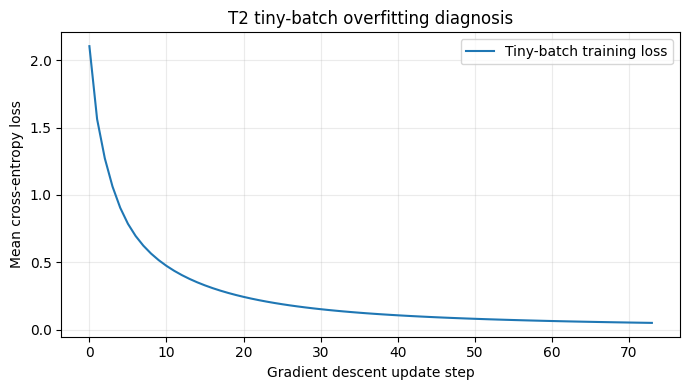

In [5]:
#Tiny batch overfit diagnostic
import matplotlib.pyplot as plt

t2_tiny_ids = [np.flatnonzero(t2_ysub == k)[0] for k in range(7)]
t2_tiny_ids.append(np.flatnonzero(t2_ysub == 3)[1])
t2_tiny_X = t2_Xsub[t2_tiny_ids]
t2_tiny_y = t2_ysub[t2_tiny_ids]
t2_tiny_model = T2NumpyMLP(seed=99)
t2_tiny_lr, t2_tiny_max_steps = 0.20, 1200
t2_tiny_threshold = 0.05
t2_tiny_losses = [t2_tiny_model.loss(t2_tiny_X, t2_tiny_y)]
for step in range(1, t2_tiny_max_steps+1):
    t2_sgd_step(t2_tiny_model,
                t2_backward(t2_tiny_model, t2_tiny_X, t2_tiny_y),
                t2_tiny_lr)
    current_loss = t2_tiny_model.loss(t2_tiny_X, t2_tiny_y)
    t2_tiny_losses.append(current_loss)
    if current_loss < t2_tiny_threshold:
        break
t2_tiny_steps = step
t2_tiny_acc = t2_tiny_model.accuracy(t2_tiny_X, t2_tiny_y)
print('Tiny training batch size:', len(t2_tiny_y))
print('Learning rate:', t2_tiny_lr)
print('Stopping rule: loss <', t2_tiny_threshold, 'or', t2_tiny_max_steps, 'steps')
print('Actual update steps completed:', t2_tiny_steps)
print('Initial loss:', round(t2_tiny_losses[0], 6))
print('Final loss:', round(t2_tiny_losses[-1], 6))
print('Tiny-batch TRAIN accuracy:', round(t2_tiny_acc, 4))
if t2_tiny_losses[-1] >= t2_tiny_threshold:
    print('DIAGNOSIS: threshold not reached; inspect learning rate, capacity or gradient behaviour.')
else:
    print('DIAGNOSIS: loss threshold reached; tiny-batch learning check succeeded.')
plt.figure(figsize=(7,4))
plt.plot(t2_tiny_losses, label='Tiny-batch training loss')
plt.xlabel('Gradient descent update step'); plt.ylabel('Mean cross-entropy loss')
plt.title('T2 tiny-batch overfitting diagnosis'); plt.legend(); plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig(t2_figures / 'T2_tiny_batch_loss.png', dpi=170)
plt.show()

 Loss falls from 2.105294 to 0.049956 within 73 update steps and training accuracy on these eight observations reaches 100%. The loss threshold is reached before the maximum step count. This supports the conclusion that the NumPy optimisation is functioning on an easy controlled check. It does not imply perfect accuracy on unseen beans

 The 73 updates are also 73 complete passes over this fixed eight-sample diagnostic batch; the separate main training run reports its epochs independently

In [6]:
# Mini-batch SGD with validation-based early stopping
T2_TRAIN_CFG = {
    'subset_seed': 2026, 'model_seed': 21, 'shuffle_seed': 22,
    'learning_rate': 0.08, 'batch_size': 64,
    'max_epochs': 180, 'patience': 20, 'min_delta': 1e-4,
    'input_dim': 16, 'hidden_dim': 24, 'output_dim': 7
}
t2_model = T2NumpyMLP(seed=T2_TRAIN_CFG['model_seed'])
t2_initial_train_loss = t2_model.loss(t2_Xsub, t2_ysub)
t2_initial_val_loss = t2_model.loss(t2_Xval, t2_yval)
print('Initial training subset loss:', round(t2_initial_train_loss, 6))
print('Initial validation loss:', round(t2_initial_val_loss, 6))

t2_rng = np.random.default_rng(T2_TRAIN_CFG['shuffle_seed'])
t2_history = []
t2_best_val = np.inf
t2_best_params = None
t2_best_epoch = 0
t2_wait = 0
t2_stopping_reason = 'Reached maximum epochs'
for epoch in range(1, T2_TRAIN_CFG['max_epochs']+1):
    order = t2_rng.permutation(len(t2_Xsub))
    for begin in range(0, len(order), T2_TRAIN_CFG['batch_size']):
        idx = order[begin:begin+T2_TRAIN_CFG['batch_size']]
        batch_grads = t2_backward(t2_model, t2_Xsub[idx], t2_ysub[idx])
        t2_sgd_step(t2_model, batch_grads, T2_TRAIN_CFG['learning_rate'])
    tr_loss = t2_model.loss(t2_Xsub, t2_ysub)
    va_loss = t2_model.loss(t2_Xval, t2_yval)
    t2_history.append({'epoch':epoch, 'train_loss':tr_loss, 'val_loss':va_loss,
                       'train_accuracy':t2_model.accuracy(t2_Xsub, t2_ysub),
                       'val_accuracy':t2_model.accuracy(t2_Xval, t2_yval)})
    if va_loss < t2_best_val - T2_TRAIN_CFG['min_delta']:
        t2_best_val = va_loss
        t2_best_params = {k:v.copy() for k,v in t2_model.params.items()}
        t2_best_epoch = epoch
        t2_wait = 0
    else:
        t2_wait += 1
    if t2_wait >= T2_TRAIN_CFG['patience']:
        t2_stopping_reason = f'Validation loss did not improve for {t2_wait} epochs'
        break

t2_epochs_completed = len(t2_history)
assert t2_best_params is not None
t2_model.params = {k:v.copy() for k,v in t2_best_params.items()}
t2_final_train_loss = t2_model.loss(t2_Xsub, t2_ysub)
t2_final_val_loss = t2_model.loss(t2_Xval, t2_yval)
t2_history_df = pd.DataFrame(t2_history)
print('Actual epochs completed:', t2_epochs_completed)
print('Early-stopping reason:', t2_stopping_reason)
print('Selected best epoch (validation):', t2_best_epoch)
print('Initial → selected training loss:', round(t2_initial_train_loss, 6), '→', round(t2_final_train_loss, 6))
print('Initial → selected validation loss:', round(t2_initial_val_loss, 6), '→', round(t2_final_val_loss, 6))
print('Selected train accuracy:', round(t2_model.accuracy(t2_Xsub,t2_ysub),4))
print('Selected validation accuracy:', round(t2_model.accuracy(t2_Xval,t2_yval),4))
if t2_final_train_loss >= t2_initial_train_loss:
    print('DIAGNOSIS: training loss did not decrease; inspect step size, scale and gradient updates.')

Initial training subset loss: 2.235258
Initial validation loss: 2.236392
Actual epochs completed: 114
Early-stopping reason: Validation loss did not improve for 20 epochs
Selected best epoch (validation): 94
Initial → selected training loss: 2.235258 → 0.189025
Initial → selected validation loss: 2.236392 → 0.216215
Selected train accuracy: 0.9303
Selected validation accuracy: 0.9257


## Final mini-batch training and interpretation

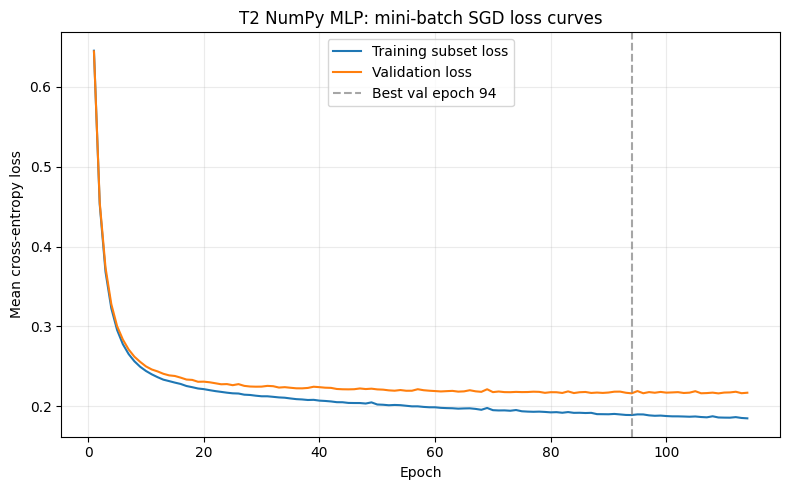

Saved T2 files:
- /content/drive/MyDrive/ANN_DryBean_CW1/artifacts/t2_gradient_check.csv
- /content/drive/MyDrive/ANN_DryBean_CW1/artifacts/t2_training_history.csv
- /content/drive/MyDrive/ANN_DryBean_CW1/artifacts/t2_numpy_mlp_weights.npz
- /content/drive/MyDrive/ANN_DryBean_CW1/artifacts/t2_training_subset_positions.npy
- /content/drive/MyDrive/ANN_DryBean_CW1/artifacts/t2_run_summary.json
- /content/drive/MyDrive/ANN_DryBean_CW1/figures/T2_tiny_batch_loss.png
- /content/drive/MyDrive/ANN_DryBean_CW1/figures/T2_train_validation_loss.png


In [7]:
# Plot true learning curves and save configuration, results, weights
plt.figure(figsize=(8,5))
plt.plot(t2_history_df['epoch'], t2_history_df['train_loss'], label='Training subset loss')
plt.plot(t2_history_df['epoch'], t2_history_df['val_loss'], label='Validation loss')
plt.axvline(t2_best_epoch, color='gray', linestyle='--', alpha=.7,
            label=f'Best val epoch {t2_best_epoch}')
plt.title('T2 NumPy MLP: mini-batch SGD loss curves')
plt.xlabel('Epoch'); plt.ylabel('Mean cross-entropy loss')
plt.grid(alpha=.25); plt.legend(); plt.tight_layout()
plt.savefig(t2_figures / 'T2_train_validation_loss.png', dpi=170)
plt.show()

t2_history_df.to_csv(t2_artifacts / 't2_training_history.csv', index=False)
np.savez_compressed(t2_artifacts / 't2_numpy_mlp_weights.npz', **t2_model.params)
np.save(t2_artifacts / 't2_training_subset_positions.npy', t2_subset_ids)
t2_summary = {
    'task': 'CW1 T2 NumPy one-hidden-layer MLP, separate from T3 framework models',
    'architecture': '16 -> 24 tanh -> 7 softmax',
    'loss': 'mean multiclass cross-entropy',
    'num_trainable_parameters':int(sum(v.size for v in t2_model.params.values())),
    'training_subset_size':int(len(t2_ysub)),
    'validation_size':int(len(t2_yval)),
    'config':T2_TRAIN_CFG,
    'actual_epochs_completed':int(t2_epochs_completed),
    'stopping_reason':t2_stopping_reason,
    'selected_best_epoch':int(t2_best_epoch),
    'initial_training_loss':float(t2_initial_train_loss),
    'selected_training_loss':float(t2_final_train_loss),
    'initial_validation_loss':float(t2_initial_val_loss),
    'selected_validation_loss':float(t2_final_val_loss),
    'selected_training_accuracy':float(t2_model.accuracy(t2_Xsub,t2_ysub)),
    'selected_validation_accuracy':float(t2_model.accuracy(t2_Xval,t2_yval)),
    'gradient_check_epsilon':T2_GRAD_EPS,
    'gradient_check_abs_tolerance':T2_ABS_TOL,
    'gradient_check_rel_tolerance':T2_REL_TOL,
    'gradient_checks_passed':int(t2_gradient_table['passed'].sum()),
    'gradient_checks_total':int(len(t2_gradient_table)),
    'tiny_batch_learning_rate':t2_tiny_lr,
    'tiny_batch_max_steps':t2_tiny_max_steps,
    'tiny_batch_actual_steps':int(t2_tiny_steps),
    'tiny_batch_initial_loss':float(t2_tiny_losses[0]),
    'tiny_batch_final_loss':float(t2_tiny_losses[-1]),
    'tiny_batch_training_accuracy':float(t2_tiny_acc),
    'python_version':sys.version.split()[0],
    'numpy_version':np.__version__,
    'machine':platform.platform(),
    'test_set_used_for_tuning':False
}
with open(t2_artifacts / 't2_run_summary.json', 'w') as f:
    json.dump(t2_summary, f, indent=2)
print('Saved T2 files:')
for filename in ['t2_gradient_check.csv','t2_training_history.csv',
                 't2_numpy_mlp_weights.npz','t2_training_subset_positions.npy','t2_run_summary.json']:
    print('-', t2_artifacts / filename)
print('-', t2_figures / 'T2_tiny_batch_loss.png')
print('-', t2_figures / 'T2_train_validation_loss.png')

In [8]:
#Reload saved weights and verify matching predictions
check_reloaded_t2 = T2NumpyMLP(seed=999)
with np.load(t2_artifacts / 't2_numpy_mlp_weights.npz') as saved:
    for key in ('W1', 'b1', 'W2', 'b2'):
        check_reloaded_t2.params[key] = saved[key].copy()
orig_probs = t2_model.forward(t2_Xsub[:5])[0]
reload_probs = check_reloaded_t2.forward(t2_Xsub[:5])[0]
assert np.allclose(orig_probs, reload_probs, atol=1e-12)
print('Reload check: PASS (probabilities match on 5 training rows)')
print('T2 T1-linked data pipeline verified; test partition not evaluated.')

Reload check: PASS (probabilities match on 5 training rows)
T2 T1-linked data pipeline verified; test partition not evaluated.
